# Importlar ve Kütüphaneler

In [1]:
!pip install -q trl
!pip install -q -U bitsandbytes
#!pip install -q -U transformers accelerate peft trl datasets
!pip install -q -U transformers datasets peft trl accelerate bitsandbytes

In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
from datasets import load_dataset, concatenate_datasets
from sklearn.model_selection import train_test_split

import os
from google.colab import userdata
from huggingface_hub import login, HfApi, create_repo

from datasets import Dataset
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, TrainingArguments

from peft import LoraConfig, TaskType, get_peft_model, PeftModel

from trl import DPOTrainer, DPOConfig

import gc

import bitsandbytes as bnb

import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

import difflib

# Hugging Face Hesabı

In [ ]:
hf_username = "anilsanli"

hf_token = userdata.get('kolektif_final')

login(token=hf_token)

Token 'kolektif_final' başarıyla alındı.
Hugging Face girişi başarılı!


# Veri Seti

In [ ]:
ds = pd.read_csv("hf://datasets/yusufbaykaloglu/Turkish-STEM-DPO-Dataset/data/full_dataset.csv")

In [ ]:
ds.head()

,sample_id,prompt,chosen,rejected,chosen_score,rejected_score,margin,subject,topic,subtopic,difficulty,chosen_tier,rejected_tier,confidence,timestamp
0,dpo_math_cebir_1757301232950_3df0200f_e11b61d0,Fonksiyon f(x) = 2x^2 - 3x + 1 olarak verilmiş...,### Problem Analizi\nVerilen fonksiyon \( f(x)...,Belirtmek.Span izi bize ezbere fonksiyonu \[ f...,9.23,2.18,7.05,math,cebir,fonksiyonlar,lise,excellent,poor,0.67,2025-09-08T03:14:14.065506
1,dpo_math_cebir_1757301254567_501221ce_f30cd5a1,Fonksiyonların tanım kümesi ve değer kümesi ar...,### 1. Problem Analizi\nVerilen fonksiyon \( f...,Verilen fonksiyon \( f(x) = 1x^2 - 3x + 1 \) b...,9.44,1.75,7.69,math,cebir,sayılar_teorisi,lise,excellent,poor,0.61,2025-09-08T03:14:34.633027
2,dpo_math_cebir_1757301275134_7e666e1e_4dd03bdd,Verilen polinom \( P(x) = 2x^3 - 5x^2 + 3x - 7...,### Problem Analizi\nVerilen polinom \( P(x) =...,Galiba Verilen polinom \( P(x) = 1x^3 - 5x^2 -...,9.39,1.88,7.51,math,cebir,polinomlar,lise,excellent,poor,0.63,2025-09-08T03:14:49.767396
3,dpo_math_cebir_1757301290269_27281950_677500d0,Fonksiyonların periodik özelliklerini kullanar...,### Problem Analizi\nVerilen fonksiyon \( f(x)...,Verilen fonksiyon:\n\[ f(x) = 2\sin(2x + \pi) ...,9.27,2.25,7.02,math,cebir,cebirsel_denklemler,lise,excellent,poor,0.68,2025-09-08T03:15:12.643535
4,dpo_math_cebir_1757301313145_01456109_84c4d732,Verilen denklem sisteminin çözümünü bulun: \(2...,### Problem Analizi\nVerilen denklem sistemi a...,Verilen denklem sistemini çözerken adım adım y...,9.20,2.17,7.03,math,cebir,modüler_aritmetik,lise,excellent,poor,0.68,2025-09-08T03:15:31.323992


# Veriyi Konu Bazlı Bölme

In [ ]:
# Konu bazlı bölme
math_df = ds[ds['subject'] == 'math']
physics_df = ds[ds['subject'] == 'physics']
prog_df = ds[ds['subject'] == 'programming']

def split_and_format_strict(subset_df, subject_name):
    train_df, test_df = train_test_split(subset_df, train_size=2000, test_size=500, random_state=429, shuffle=True)

    train_df = train_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    train_dataset = Dataset.from_pandas(train_df)
    test_dataset = Dataset.from_pandas(test_df)

    print(f"{subject_name} -> Train: {len(train_dataset)}, Test: {len(test_dataset)}")
    return train_dataset, test_dataset

train_math, test_math = split_and_format_strict(math_df, "Math")
train_phys, test_phys = split_and_format_strict(physics_df, "Physics")
train_prog, test_prog = split_and_format_strict(prog_df, "Programming")

Math -> Train: 2000, Test: 500
Physics -> Train: 2000, Test: 500
Programming -> Train: 2000, Test: 500


# Turkish-Llama-8b-DPO-v0.1

In [ ]:
model_name = "ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

...

model-00003-of-00004.safetensors:   0%|          | 0.00/4.92G [00:00<?, ?B/s]

model-00004-of-00004.safetensors:   0%|          | 0.00/1.17G [00:00<?, ?B/s]

model-00002-of-00004.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/172 [00:00<?, ?B/s]

In [ ]:
model_name = "ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1"

# 4-bit Quantization Ayarları
# Bu ayar modelin bellekte çok daha az yer kaplamasını sağlar.
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

# Modeli Yükleme
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16
)

tokenizer = AutoTokenizer.from_pretrained(model_name)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model.config.pad_token_id = tokenizer.pad_token_id

print("Model ve Tokenizer, QLoRA eğitimi için başarıyla yüklendi.")

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Model ve Tokenizer, QLoRA eğitimi için başarıyla yüklendi.


# LoRA Konfigürasyonu

In [ ]:
peft_config = LoraConfig(
    # Rank (r): Adaptör matrislerinin boyutu.
    r=16,

    # Alpha: Öğrenme katsayısı çarpanı. Genelde r'nin 2 katı seçilir.
    lora_alpha=32,

    lora_dropout=0.05,

    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', "gate_proj", "up_proj", "down_proj"],

    bias="none",

    task_type=TaskType.CAUSAL_LM,
)

print("LoRA konfigürasyonu hazırlandı.")

LoRA konfigürasyonu hazırlandı.


# Uzman Eğitimi

In [ ]:
def train_subject_low_lr(subject_name, train_ds, test_ds, model, tokenizer, peft_config):

    print(f"{subject_name} Eğitimi Başlıyor")

    local_output_dir = f"./local_adapter_{subject_name.lower()}"
    checkpoint_dir = f"./checkpoints_{subject_name}"

    training_args = DPOConfig(
        output_dir=checkpoint_dir,
        per_device_train_batch_size=1,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=8,

        learning_rate=1e-6,
        num_train_epochs=1,

        eval_strategy="steps",

        eval_steps=50,
        logging_steps=20,

        save_strategy="steps",
        save_steps=50,
        save_total_limit=2,

        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,

        optim="paged_adamw_32bit",
        fp16=False,
        bf16=True,
        report_to="none",
        remove_unused_columns=False,
        gradient_checkpointing=True,

        # DPO Ayarları
        beta=0.1,
        max_length=2048,
        max_prompt_length=1024,
    )

    dpo_trainer = DPOTrainer(
        model=model,
        ref_model=None,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=test_ds,
        processing_class=tokenizer,
        peft_config=peft_config,
    )

    # Eğitimi Başlat
    dpo_trainer.train()

    # Yerel Diske En İyi Modeli Kaydet
    print(f"En iyi model yerel diske kaydediliyor: {local_output_dir}")
    dpo_trainer.model.save_pretrained(local_output_dir)
    tokenizer.save_pretrained(local_output_dir)

    print(f"{subject_name} eğitimi bitti. Dosya konumu: '{local_output_dir}'")
    return local_output_dir

In [ ]:
RUN_LIST = ["Math", "Physics", "Programming"]

# Hafıza temizliği
def flush_memory():
    gc.collect()
    torch.cuda.empty_cache()

subjects_queue = [
    ("Math", train_math, test_math),
    ("Physics", train_phys, test_phys),
    ("Programming", train_prog, test_prog)
]

saved_paths = {}

for subject, train_data, test_data in subjects_queue:

    print(f"🔄 {subject} Uzmanı Eğitiliyor")

    flush_memory()

    # Modeli Yükle
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
    )

    # Global model_name değişkeni
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        quantization_config=bnb_config,
        device_map="auto",
        torch_dtype=torch.bfloat16
    )

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model.config.pad_token_id = tokenizer.pad_token_id

    # EĞİTİMİ BAŞLAT
    path = train_subject_low_lr(subject, train_data, test_data, model, tokenizer, peft_config)

    saved_paths[subject] = path

    # Temizlik
    print(f"🧹 {subject} bitti.")
    del model
    del tokenizer
    flush_memory()

print("\nSeçilen tüm eğitimler tamamlandı.")

🚀 --- EĞİTİM MODU BAŞLATILIYOR ---
📋 Çalıştırılacak Dersler: ['Math']



🔄 ===================================================
🔄 SÜREÇ: Math Uzmanı Eğitiliyor...
🔄 ===================================================
📥 Model ve Tokenizer Yükleniyor...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]


🚀 --- Math Eğitimi Başlıyor (Düşük Learning Rate) ---


Extracting prompt in train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Applying chat template to train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

...

Applying chat template to eval dataset:   0%|          | 0/500 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/500 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 128009}.


Step,Training Loss,Validation Loss,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected,Logits/chosen,Logits/rejected
50,0.272500,0.116676,1.815942,-0.342957,1.000000,2.158899,-728.560425,-902.502991,1.287774,0.470334
100,0.024600,0.015824,3.652619,-0.834986,1.000000,4.487605,-710.193665,-907.423279,1.291575,0.490995
150,0.007400,0.005365,4.688024,-1.155477,1.000000,5.843501,-699.839539,-910.628174,1.293468,0.502638
200,0.004400,0.003960,5.009332,-1.281191,1.000000,6.290524,-696.626526,-911.885315,1.294192,0.506960
250,0.003400,0.003549,5.117057,-1.324664,1.000000,6.441721,-695.549316,-912.320068,1.294425,0.508232


💾 En iyi model (Best Checkpoint) yerel diske kaydediliyor: ./local_adapter_math
✅ Math eğitimi bitti. Dosyalar './local_adapter_math' klasöründe bekliyor.
🧹 Math bitti. Bellek temizleniyor...
⏩ ATLANIYOR: Physics (Listede seçili değil)
⏩ ATLANIYOR: Programming (Listede seçili değil)

🏁 Seçilen tüm eğitimler tamamlandı.
Kaydedilen Klasör Yolları: {'Math': './local_adapter_math'}


In [ ]:
hf_username = "anilsanli"

def push_local_model_to_hub(local_path, subject_name, username):

    repo_name = f"{username}/Turkish-Llama-DPO-{subject_name}-Adapter"

    print(f"Yükleniyor: {repo_name}")

    try:
        api = HfApi()

        # Repoyu oluştur
        create_repo(repo_name, exist_ok=True, repo_type="model")

        # Klasörü olduğu gibi yükle
        api.upload_folder(
            folder_path=local_path,
            repo_id=repo_name,
            repo_type="model"
        )

        print(f"Model HuggingFace'e kaydedildi: {repo_name}")

    except Exception as e:
        print(f"Hata ({subject_name}): {e}")

# ÇALIŞTIRMA BÖLÜMÜ

manual_list = [
    ("Math", "./local_adapter_math"),
    ("Physics", "./local_adapter_physics"),
    ("Programming", "./local_adapter_programming")
]

for subject, path in manual_list:
    if os.path.exists(path):
        push_local_model_to_hub(path, subject, hf_username)
    else:
        print(f"'{path}' klasörü bulunamadı.")

👤 Kullanıcı: anilsanli
🚀 Hugging Face yükleme işlemi başlatılıyor...


☁️  Yükleniyor: anilsanli/Turkish-Llama-DPO-Physics-Adapter ...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...er_physics/tokenizer.json: 100%|##########| 17.2MB / 17.2MB            

  ...adapter_model.safetensors:   4%|3         | 6.03MB /  168MB            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...rogramming/tokenizer.json: 100%|##########| 17.2MB / 17.2MB            

  ...adapter_model.safetensors:   2%|2         | 3.89MB /  168MB            

✅ Model saved to HuggingFace Hub: anilsanli/Turkish-Llama-DPO-Programming-Adapter
🔗 Link: https://huggingface.co/anilsanli/Turkish-Llama-DPO-Programming-Adapter


# Model Merge

In [ ]:
hf_username = "anilsanli"
base_model_id = "ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1"

# Birleştirilecek Adaptörlerin Listesi
adapters_to_merge = [
    f"{hf_username}/Turkish-Llama-DPO-Math-Adapter",
    f"{hf_username}/Turkish-Llama-DPO-Physics-Adapter",
    f"{hf_username}/Turkish-Llama-DPO-Programming-Adapter"
]

collective_repo_name = f"{hf_username}/Turkish-Llama-Kolektif-DPO-v1"

print("Model birleştirme işlemi")

# Base Model
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16
)
tokenizer = AutoTokenizer.from_pretrained(base_model_id)

print("Uzmanlar modele bağlanıyor...")

model = PeftModel.from_pretrained(model, adapters_to_merge[0], adapter_name="math")
print(f"   + Math yüklendi.")

model.load_adapter(adapters_to_merge[1], adapter_name="physics")
print(f"   + Physics yüklendi.")

model.load_adapter(adapters_to_merge[2], adapter_name="programming")
print(f"   + Programming yüklendi.")

# Birleştirme
# Hepsine 1.0 ağırlık vererek linear birleştirme
print("Modeller birleştiriliyor")

model.add_weighted_adapter(
    adapters=["math", "physics", "programming"],
    weights=[1.0, 1.0, 1.0],
    adapter_name="kolektif_uzman",
    combination_type="linear"
)

model.set_adapter("kolektif_uzman")

print("Tüm yetenekler 'kolektif_uzman' altında toplandı.")

print(f"Kolektif Adaptör Hugging Face'e yükleniyor: {collective_repo_name}")

try:
    local_merge_path = "./local_collective_adapter"
    model.save_pretrained(local_merge_path)
    tokenizer.save_pretrained(local_merge_path)

    api = HfApi()
    create_repo(collective_repo_name, exist_ok=True, repo_type="model")

    api.upload_folder(
        folder_path=local_merge_path,
        repo_id=collective_repo_name,
        repo_type="model"
    )

    print(f"Kolektif Model Yüklendi!")

except Exception as e:
    print(f"Yükleme hatası: {e}")

🚀 --- KOLEKTİF MERGE (BİRLEŞTİRME) İŞLEMİ BAŞLIYOR ---
📥 Base Model yükleniyor: ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]


🔗 Uzmanlar modele bağlanıyor...
   + Math yüklendi.


adapter_config.json: 0.00B [00:00, ?B/s]

adapter_model.safetensors:   0%|          | 0.00/168M [00:00<?, ?B/s]

...

  ...ve_adapter/tokenizer.json: 100%|##########| 17.2MB / 17.2MB            

  ...adapter_model.safetensors:  20%|#9        | 33.5MB /  168MB            

  ...adapter_model.safetensors:  20%|#9        | 33.5MB /  168MB            

  ...adapter_model.safetensors:   1%|1         | 2.21MB /  168MB            

🎉 TEBRİKLER! Kolektif Model Yayında!
🔗 Link: https://huggingface.co/anilsanli/Turkish-Llama-Kolektif-DPO-v1
Artık bu linki kullanarak 3 konuyu da bilen tek bir model çağırabilirsin.


# Toplu Eğitim

In [ ]:
def flush_memory():
    gc.collect()
    torch.cuda.empty_cache()

flush_memory()

print("Veri setleri birleştiriliyor ve karıştırılıyor...")

full_train_dataset = concatenate_datasets([train_math, train_phys, train_prog])

full_train_dataset = full_train_dataset.shuffle(seed=42)

full_test_dataset = concatenate_datasets([test_math, test_phys, test_prog])
full_test_dataset = full_test_dataset.shuffle(seed=42)

print(f"Eğitim Verisi Sayısı: {len(full_train_dataset)}")
print(f"Test Verisi Sayısı: {len(full_test_dataset)}")

# Base Model
hf_username = "anilsanli"
base_model_id = "ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1"
new_model_name = "Turkish-Llama-DPO-Mixed-Baseline"

print(f"Base Model Yükleniyor: {base_model_id}")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16
)

tokenizer = AutoTokenizer.from_pretrained(base_model_id)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = tokenizer.pad_token_id

# LoRA Ayarları
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', "gate_proj", "up_proj", "down_proj"],
    bias="none",
    task_type=TaskType.CAUSAL_LM,
)

print(f"Toplu eğitim başlıyor")
local_output_dir = "./local_adapter_mixed_baseline"

training_args = DPOConfig(
    output_dir="./checkpoints_mixed",
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,

    learning_rate=1e-6,
    num_train_epochs=1,

    eval_strategy="steps",
    eval_steps=100,
    logging_steps=50,

    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    optim="paged_adamw_32bit",
    fp16=False,
    bf16=True,
    report_to="none",
    remove_unused_columns=False,
    gradient_checkpointing=True,

    beta=0.1,
    max_length=2048,
    max_prompt_length=1024,
)

dpo_trainer = DPOTrainer(
    model=model,
    ref_model=None,
    args=training_args,
    train_dataset=full_train_dataset,
    eval_dataset=full_test_dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)

dpo_trainer.train()

print(f"Eğitim tamamlandı. Yerel diske kaydediliyor.")
dpo_trainer.model.save_pretrained(local_output_dir)
tokenizer.save_pretrained(local_output_dir)

repo_id = f"{hf_username}/{new_model_name}"
print(f"Hugging Face'e yükleniyor: {repo_id}")

try:
    api = HfApi()
    create_repo(repo_id, exist_ok=True, repo_type="model")
    api.upload_folder(
        folder_path=local_output_dir,
        repo_id=repo_id,
        repo_type="model"
    )
    print(f"Toplu Model Linki: https://huggingface.co/{repo_id}")

except Exception as e:
    print(f"Yükleme hatası: {e}")

# Temizlik
del model
del tokenizer
flush_memory()

🔄 Veri setleri birleştiriliyor ve karıştırılıyor...
✅ Toplu Veri Hazır!
   Eğitim Verisi Sayısı: 6000
   Test Verisi Sayısı: 1500

📥 Base Model Yükleniyor: ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          |  543kB /  168MB            

  ...d_baseline/tokenizer.json: 100%|##########| 17.2MB / 17.2MB            

🎉 Başarılı! Toplu Model Linki: https://huggingface.co/anilsanli/Turkish-Llama-DPO-Mixed-Baseline


# Değerlendirme

In [ ]:
# Veriyi Hugging Face'den çek
try:
    full_ds = load_dataset("yusufbaykaloglu/Turkish-STEM-DPO-Dataset", split="train")
except Exception as e:
    print(f"Veri indirme hatası: {e}")
    raise e

def get_test_subset(dataset, subject_name):
    subset = dataset.filter(lambda x: x['subject'] == subject_name)

    subset = subset.shuffle(seed=429)
    if len(subset) < 2500:
        return subset.select(range(int(len(subset)*0.8), len(subset)))
    else:
        return subset.select(range(2000, 2500))

test_math = get_test_subset(full_ds, "math")
test_phys = get_test_subset(full_ds, "physics")
test_prog = get_test_subset(full_ds, "programming")

# Ayarlar
hf_username = "anilsanli"
base_model_id = "ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1"

models_to_test = [
    ("Sadece Matematik", f"{hf_username}/Turkish-Llama-DPO-Math-Adapter"),
    ("Sadece Fizik",     f"{hf_username}/Turkish-Llama-DPO-Physics-Adapter"),
    ("Sadece Yazılım",   f"{hf_username}/Turkish-Llama-DPO-Programming-Adapter"),
    ("KOLEKTİF (Merge)", f"{hf_username}/Turkish-Llama-Kolektif-DPO-v1"),
    ("TOPLU (Mixed)",    f"{hf_username}/Turkish-Llama-DPO-Mixed-Baseline")
]

test_sets = [
    ("Math Test", test_math),
    ("Physics Test", test_phys),
    ("Programming Test", test_prog)
]

results = []

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

# Test döngüsü
for model_name, adapter_id in models_to_test:

    print(f"Model Yükleniyor: {model_name}...")
    gc.collect()
    torch.cuda.empty_cache()

    try:
        # Base Model
        model = AutoModelForCausalLM.from_pretrained(
            base_model_id,
            quantization_config=bnb_config,
            device_map="auto",
            torch_dtype=torch.bfloat16
        )
        tokenizer = AutoTokenizer.from_pretrained(base_model_id)
        if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token

        # Adaptör
        try:
            model = PeftModel.from_pretrained(model, adapter_id)
        except Exception as e:
            print(f"Adaptör yüklenemedi: {e}")
            continue

    except Exception as e:
        print(f"Model yükleme hatası: {e}")
        continue

    # Testler
    for test_name, dataset in test_sets:
        print(f"Konu: {test_name} ({len(dataset)} soru)")

        try:
            dpo_evaluator = DPOTrainer(
                model=model,
                ref_model=None,
                args=DPOConfig(
                    output_dir="temp_eval",
                    per_device_eval_batch_size=1,
                    remove_unused_columns=False,
                    report_to="none"
                ),
                train_dataset=dataset,
                eval_dataset=dataset,
                processing_class=tokenizer,
            )

            metrics = dpo_evaluator.evaluate()
            loss = metrics.get('eval_loss', 99.9)
            print(f"Skor (Loss): {loss:.4f}")

            results.append({
                "Model": model_name,
                "Test Seti": test_name,
                "Loss": loss
            })

        except Exception as e:
            print(f"Hata: {e}")
            results.append({"Model": model_name, "Test Seti": test_name, "Loss": 99.9})

    del model
    del tokenizer

# Sonuç
print("Sonuçlar")
if results:
    df_results = pd.DataFrame(results)
    pivot_table = df_results.pivot(index="Model", columns="Test Seti", values="Loss")
    print(pivot_table.to_markdown())
    pivot_table.to_csv("Proje_Karsilastirma_Sonuclari.csv")
else:
    print("Sonuç alınamadı.")

🔄 Veriler hazırlanıyor...


README.md: 0.00B [00:00, ?B/s]

data/full_dataset.csv:   0%|          | 0.00/83.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/16177 [00:00<?, ? examples/s]

Filter:   0%|          | 0/16177 [00:00<?, ? examples/s]

...

adapter_model.safetensors:   0%|          | 0.00/168M [00:00<?, ?B/s]

   ↳ Sınav: Math Test (500 soru)...


      ✅ Skor (Loss): 0.0156
   ↳ Sınav: Physics Test (500 soru)...


      ✅ Skor (Loss): 0.0035
   ↳ Sınav: Programming Test (500 soru)...


      ✅ Skor (Loss): 0.0144


🏆 --- FİNAL SONUÇLARI --- 🏆
| Model            |   Math Test |   Physics Test |   Programming Test |
|:-----------------|------------:|---------------:|-------------------:|
| Sadece Fizik     |   0.139889  |     0.0460752  |          0.25548   |
| Sadece Matematik |   0.0628809 |     0.06394    |          0.196173  |
| Sadece Yazılım   |   0.13228   |     0.0975062  |          0.0758533 |
| TOPLU (Mixed)    |   0.0155854 |     0.00350058 |          0.0144152 |


In [ ]:
#Kolektif model onarım

hf_username = "anilsanli"
base_model_id = "ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1"

adapters_to_merge = [
    f"{hf_username}/Turkish-Llama-DPO-Math-Adapter",
    f"{hf_username}/Turkish-Llama-DPO-Physics-Adapter",
    f"{hf_username}/Turkish-Llama-DPO-Programming-Adapter"
]

collective_repo_name = f"{hf_username}/Turkish-Llama-Kolektif-DPO-v1"
local_merge_path = "./local_collective_adapter_FIXED"

print(f"📥 Base Model Yükleniyor...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16
)
tokenizer = AutoTokenizer.from_pretrained(base_model_id)

try:

    model = PeftModel.from_pretrained(model, adapters_to_merge[0], adapter_name="math")

    model.load_adapter(adapters_to_merge[1], adapter_name="physics")

    model.load_adapter(adapters_to_merge[2], adapter_name="programming")

    print("Birleştirme yapılıyor...")
    model.add_weighted_adapter(
        adapters=["math", "physics", "programming"],
        weights=[1.0, 1.0, 1.0],
        adapter_name="kolektif_uzman",
        combination_type="linear"
    )
    model.set_adapter("kolektif_uzman")
    print("Birleştirme Başarılı.")

except Exception as e:
    print(f"Birleştirme sırasında hata: {e}")
    exit()

print(f"Yerel diske kaydediliyor: {local_merge_path}")
model.save_pretrained(local_merge_path)
tokenizer.save_pretrained(local_merge_path)

print(f"Hugging Face'e yükleniyor: {collective_repo_name}")
try:
    api = HfApi()
    create_repo(collective_repo_name, exist_ok=True, repo_type="model")

    api.upload_folder(
        folder_path=local_merge_path,
        repo_id=collective_repo_name,
        repo_type="model"
    )
    print(f"Onarım tamamlandı")

except Exception as e:
    print(f"Yükleme hatası: {e}")

🛠️ --- KOLEKTİF MODEL ONARIM MODU BAŞLATILIYOR ---
📥 Base Model Yükleniyor...


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

🔗 Uzmanlar yükleniyor ve birleştiriliyor...
⚗️  Birleştirme (Weighted Merge) yapılıyor...
✅ Birleştirme Başarılı.

💾 Yerel diske kaydediliyor: ./local_collective_adapter_FIXED
❌ HATA: Dosya hala yok! Kayıt işleminde bir sorun var.

☁️  Hugging Face'e yükleniyor: anilsanli/Turkish-Llama-Kolektif-DPO-v1


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

  ...adapter_model.safetensors:  25%|##4       | 41.9MB /  168MB            

  ...adapter_model.safetensors:  20%|#9        | 33.5MB /  168MB            

  ...adapter_model.safetensors:  25%|##4       | 41.9MB /  168MB            

  ...pter_FIXED/tokenizer.json: 100%|##########| 17.2MB / 17.2MB            

🎉 ONARIM TAMAMLANDI! Model linki: https://huggingface.co/anilsanli/Turkish-Llama-Kolektif-DPO-v1


In [ ]:
try:
    full_ds = load_dataset("yusufbaykaloglu/Turkish-STEM-DPO-Dataset", split="train")
except Exception as e:
    print(f"Veri hatası: {e}")
    raise e

def get_test_subset(dataset, subject_name):
    subset = dataset.filter(lambda x: x['subject'] == subject_name)
    subset = subset.shuffle(seed=429)

    if len(subset) < 2500:
        return subset.select(range(int(len(subset)*0.8), len(subset)))
    else:
        return subset.select(range(2000, 2500))

test_math = get_test_subset(full_ds, "math")
test_phys = get_test_subset(full_ds, "physics")
test_prog = get_test_subset(full_ds, "programming")

test_sets = [
    ("Math Test", test_math),
    ("Physics Test", test_phys),
    ("Programming Test", test_prog)
]

# Modeli birleştir
hf_username = "anilsanli"
base_model_id = "ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1"

adapters_to_merge = [
    f"{hf_username}/Turkish-Llama-DPO-Math-Adapter",
    f"{hf_username}/Turkish-Llama-DPO-Physics-Adapter",
    f"{hf_username}/Turkish-Llama-DPO-Programming-Adapter"
]

# Temizlik
gc.collect()
torch.cuda.empty_cache()

# A) Base Model
print(f"Base Model Yükleniyor...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16
)
tokenizer = AutoTokenizer.from_pretrained(base_model_id)
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token

# B) Adaptörleri Tek Tek Yükle

# 1. Matematik
model = PeftModel.from_pretrained(model, adapters_to_merge[0], adapter_name="math")
print("   + Math yüklendi.")

# 2. Fizik
model.load_adapter(adapters_to_merge[1], adapter_name="physics")
print("   + Physics yüklendi.")

# 3. Yazılım
model.load_adapter(adapters_to_merge[2], adapter_name="programming")
print("   + Programming yüklendi.")

# C) Birleştirme (Merge)
model.add_weighted_adapter(
    adapters=["math", "physics", "programming"],
    weights=[1.0, 1.0, 1.0],  # Eşit ağırlık
    adapter_name="kolektif_uzman",
    combination_type="linear"
)

# D) Aktif Et
model.set_adapter("kolektif_uzman")
print("Kolektif model hazır.")

#Test
results = []
model_name = "KOLEKTİF (RAM Merge)"

print(f"Testler Başlıyor: {model_name}")

for test_name, dataset in test_sets:
    print(f"Konu: {test_name} ({len(dataset)} soru)")

    try:
        # Evaluate
        dpo_evaluator = DPOTrainer(
            model=model,
            ref_model=None,
            args=DPOConfig(
                output_dir="temp_eval",
                per_device_eval_batch_size=1,
                remove_unused_columns=False,
                report_to="none"
            ),
            train_dataset=dataset,
            eval_dataset=dataset,
            processing_class=tokenizer,
        )

        metrics = dpo_evaluator.evaluate()
        loss = metrics.get('eval_loss', 99.9)
        print(f"Skor (Loss): {loss:.4f}")

        results.append({
            "Model": model_name,
            "Test Seti": test_name,
            "Loss": loss
        })

    except Exception as e:
        print(f"Hata: {e}")
        results.append({"Model": model_name, "Test Seti": test_name, "Loss": 99.9})

# Sonuç
print("--- Kolektif Model Sonuçları --- ")
if results:
    df_results = pd.DataFrame(results)
    print(df_results.to_markdown(index=False))
else:
    print("Sonuç yok.")

🔄 Veriler hazırlanıyor...
✅ Veriler Hazır.

🚀 --- KOLEKTİF MODEL: CANLI BİRLEŞTİRME VE TEST ---
📥 Base Model Yükleniyor...


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

🔗 Uzmanlar hafızaya alınıyor...
   + Math yüklendi.
   + Physics yüklendi.
   + Programming yüklendi.
⚗️  Hafızada Birleştiriliyor (Weighted Combination)...
✅ KOLEKTİF MODEL HAZIR (RAM'de çalışıyor).

📊 Testler Başlıyor: KOLEKTİF (RAM Merge)
   ↳ Sınav: Math Test (500 soru)...


      ✅ Skor (Loss): 0.0189
   ↳ Sınav: Physics Test (500 soru)...


      ✅ Skor (Loss): 0.0002
   ↳ Sınav: Programming Test (500 soru)...


      ✅ Skor (Loss): 0.0015


🏆 --- KOLEKTİF MODEL SONUÇLARI --- 🏆
| Model                | Test Seti        |        Loss |
|:---------------------|:-----------------|------------:|
| KOLEKTİF (RAM Merge) | Math Test        | 0.0189123   |
| KOLEKTİF (RAM Merge) | Physics Test     | 0.000172532 |
| KOLEKTİF (RAM Merge) | Programming Test | 0.00153908  |


# Görselleştirme

In [ ]:
#Loss verilerinin manuel işlenmesi (Farklı oturumda çalıştığından dolayı outputlardan kopyalanmıştır)
def plot_learning_curves_full():

    math_steps = [50, 100, 150, 200, 250]
    math_loss = [0.2725, 0.0246, 0.0074, 0.0044, 0.0034]

    phys_steps = [50, 100, 150, 200, 250]
    phys_loss = [0.1978, 0.0088, 0.0033, 0.0021, 0.0016]

    prog_steps = [50, 100, 150, 200, 250]
    prog_loss = [0.3251	, 0.0492, 0.0186, 0.0061, 0.0064]

    mixed_steps = [100, 200, 300, 400, 500, 600, 700]
    mixed_loss = [0.0611, 0.0044, 0.0012, 0.0014, 0.0007, 0.0007, 0.0007]

    plt.figure(figsize=(12, 7))

    plt.plot(math_steps, math_loss, marker='o', label='Matematik Uzmanı', color='#1f77b4', linestyle='--', linewidth=2)
    plt.plot(phys_steps, phys_loss, marker='s', label='Fizik Uzmanı', color='#ff7f0e', linestyle='--', linewidth=2)
    plt.plot(prog_steps, prog_loss, marker='D', label='Yazılım Uzmanı', color='#2ca02c', linestyle='--', linewidth=2) # YEŞİL ÇİZGİ EKLENDİ
    plt.plot(mixed_steps, mixed_loss, marker='^', label='Toplu (Mixed) Model', color='#d62728', linewidth=3)

    plt.title('Modellerin Öğrenme Süreçleri (Training Loss)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Eğitim Adımı (Steps)', fontweight='bold')
    plt.ylabel('Hata Değeri (Log Scale)', fontweight='bold')
    plt.yscale('log')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    plt.legend(fontsize=11)

    plt.tight_layout()
    plt.savefig("grafik_egitim_sureci_tam.png", dpi=300)
    plt.show()

plot_learning_curves_full()

📊 Grafik (Sadece Yazılım Dahil) oluşturuluyor...


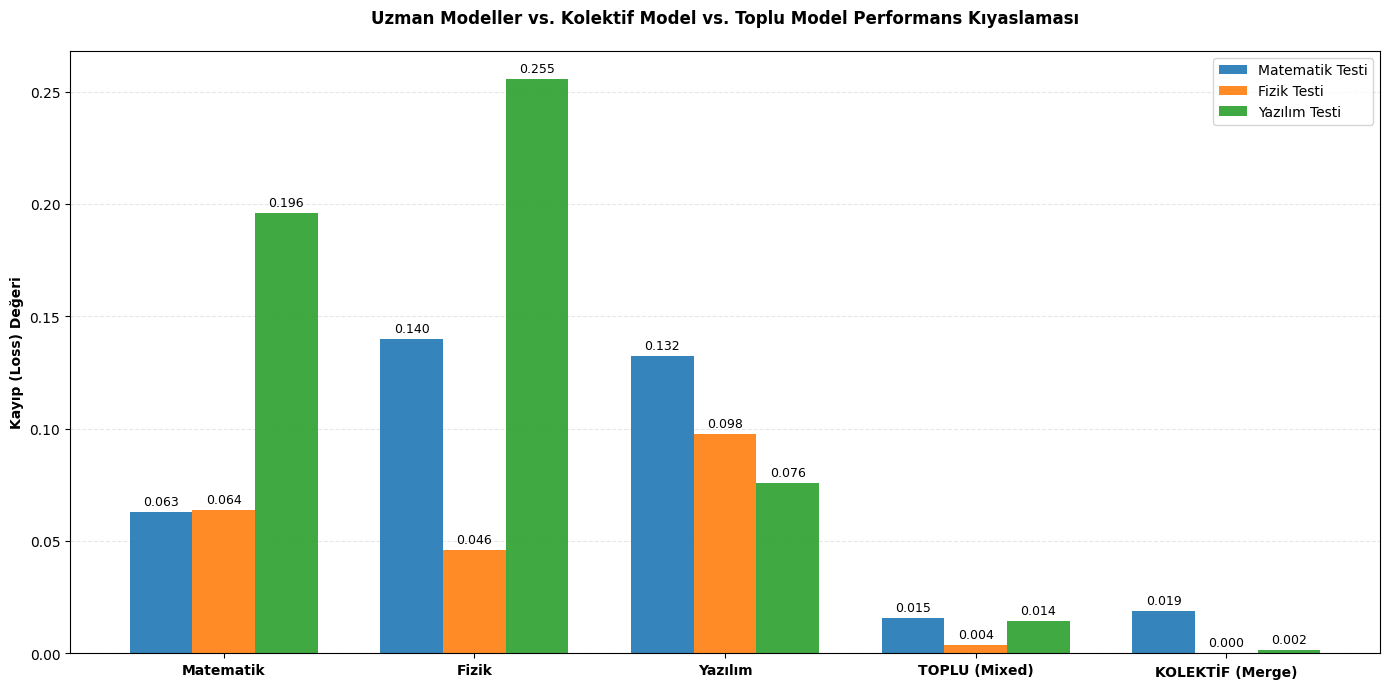

✅ Grafik oluşturuldu.


In [ ]:
#Loss verilerinin manuel işlenmesi (Farklı oturumda çalıştığından dolayı outputlardan kopyalanmıştır)
data = {
    "Model": ["Matematik", "Fizik", "Yazılım", "TOPLU (Mixed)", "KOLEKTİF (Merge)"],

    # Matematik
    "Math Loss": [0.0628, 0.1398, 0.1322, 0.0155, 0.0189],

    # Fizik
    "Physics Loss": [0.0639, 0.0460, 0.0975, 0.0035, 0.0001],

    # Programlama
    "Prog. Loss": [0.1961, 0.2554, 0.0758, 0.0144, 0.0015]
}

df = pd.DataFrame(data)

#Grafik
def plot_benchmark(dataframe):
    labels = dataframe["Model"]
    math_vals = dataframe["Math Loss"]
    phys_vals = dataframe["Physics Loss"]
    prog_vals = dataframe["Prog. Loss"]

    x = np.arange(len(labels))
    width = 0.25

    fig, ax = plt.subplots(figsize=(14, 7))

    rects1 = ax.bar(x - width, math_vals, width, label='Matematik Testi', color='#1f77b4', alpha=0.9)
    rects2 = ax.bar(x, phys_vals, width, label='Fizik Testi', color='#ff7f0e', alpha=0.9)
    rects3 = ax.bar(x + width, prog_vals, width, label='Yazılım Testi', color='#2ca02c', alpha=0.9)

    ax.set_ylabel('Kayıp (Loss) Değeri', fontweight='bold')
    ax.set_title('Uzman Modeller vs. Kolektif Model vs. Toplu Model Performans Kıyaslaması', fontweight='bold', pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontweight='bold')
    ax.legend()

    ax.yaxis.grid(True, linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)

    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.3f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, rotation=0)

    autolabel(rects1)
    autolabel(rects2)
    autolabel(rects3)

    plt.tight_layout()
    plt.savefig("proje_final_grafigi_duzeltilmis.png", dpi=300)
    plt.show()

plot_benchmark(df)


🔥 Isı Haritası Çiziliyor...


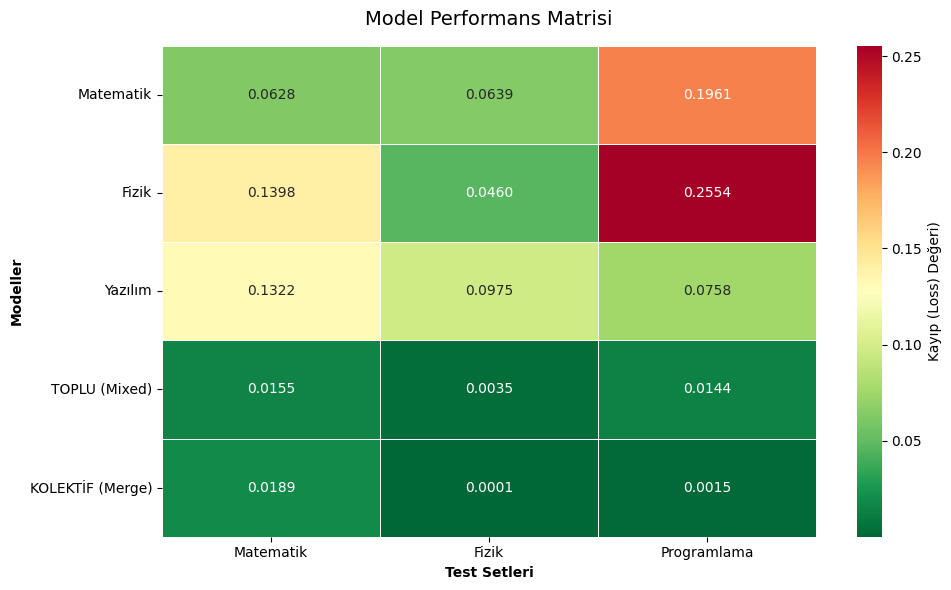

In [ ]:
#Loss verilerinin manuel işlenmesi (Farklı oturumda çalıştığından dolayı outputlardan kopyalanmıştır)
models = ["Matematik", "Fizik", "Yazılım", "TOPLU (Mixed)", "KOLEKTİF (Merge)"]
data = {
    "Matematik": [0.0628, 0.1398, 0.1322, 0.0155, 0.0189],
    "Fizik": [0.0639, 0.0460, 0.0975, 0.0035, 0.0001],
    "Programlama": [0.1961, 0.2554, 0.0758, 0.0144, 0.0015]
}

def plot_heatmap():
    df_heatmap = pd.DataFrame(data, index=models)

    plt.figure(figsize=(10, 6))

    sns.heatmap(df_heatmap, annot=True, fmt=".4f", cmap="RdYlGn_r", linewidths=.5, cbar_kws={'label': 'Kayıp (Loss) Değeri)'})

    plt.title('Model Performans Matrisi', size=14, pad=15)
    plt.ylabel('Modeller', fontweight='bold')
    plt.xlabel('Test Setleri', fontweight='bold')
    plt.xticks(rotation=0)
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.savefig("proje_heatmap.png", dpi=300)
    plt.show()

plot_heatmap()

# Soru ve Cevap Setleri

In [ ]:
def calculate_similarity(text1, text2):
    """İki metin arasındaki benzerlik oranını (0-100 arası) hesaplar."""
    if not text1 or not text2: return 0.0
    matcher = difflib.SequenceMatcher(None, text1, text2)
    return matcher.ratio() * 100

def get_verdict(gen_text, chosen_text, rejected_text):
    """
    Cevabın hangisine daha yakın olduğunu belirler.
    """
    score_chosen = calculate_similarity(gen_text, chosen_text)
    score_rejected = calculate_similarity(gen_text, rejected_text)

    # Eşitlik durumunda Chosen lehine karar verilir
    if score_chosen >= score_rejected:
        return "✅ Chosen (Doğru)", score_chosen, score_rejected
    else:
        return "❌ Rejected (Kötü)", score_chosen, score_rejected

print("📊 Veri seti indiriliyor ve 5'er örnek soru seçiliyor...")

try:
    full_ds = load_dataset("yusufbaykaloglu/Turkish-STEM-DPO-Dataset", split="train")

    def get_questions(subject, count=5):
        subset = full_ds.filter(lambda x: x['subject'] == subject)
        start_idx = 2000 if len(subset) > 2000 else 0
        indices = random.sample(range(start_idx, len(subset)), count)
        return [subset[i] for i in indices]

    math_qs = get_questions("math", 5)
    phys_qs = get_questions("physics", 5)
    prog_qs = get_questions("programming", 5)

    all_questions = math_qs + phys_qs + prog_qs
    subjects = ["Matematik"]*5 + ["Fizik"]*5 + ["Yazılım"]*5

    print(f"Toplam {len(all_questions)} soru hazırlandı")

except Exception as e:
    print(f"Veri hatası: {e}")
    all_questions = []

# Model ve adaptör yükleme
hf_username = "anilsanli"
base_model_id = "ytu-ce-cosmos/Turkish-Llama-8b-DPO-v0.1"
results_data = []

gc.collect()
torch.cuda.empty_cache()

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16
)
tokenizer = AutoTokenizer.from_pretrained(base_model_id)

# Modeller Listesi
models_list = [
    ("Matematik", f"{hf_username}/Turkish-Llama-DPO-Math-Adapter"),
    ("Fizik",     f"{hf_username}/Turkish-Llama-DPO-Physics-Adapter"),
    ("Yazılım",   f"{hf_username}/Turkish-Llama-DPO-Programming-Adapter"),
    ("KOLEKTİF (Merge)", "RAM_MERGE_YAPILACAK")
]

# Test döngüsü
def run_test_for_model(model_display_name):
    print(f"Test Ediliyor: {model_display_name}...")

    for i, q_data in enumerate(all_questions):
        prompt = q_data['prompt']
        chosen = q_data['chosen']
        rejected = q_data['rejected']
        subject = subjects[i]

        # Cevap Üret
        messages = [{"role": "user", "content": prompt}]
        text_input = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer(text_input, return_tensors="pt").to(model.device)

        with torch.no_grad():
            outputs = model.generate(**inputs, max_new_tokens=100, do_sample=True, temperature=0.5)

        response = tokenizer.decode(outputs[0][inputs['input_ids'].shape[-1]:], skip_special_tokens=True)

        # Analiz
        verdict, score_c, score_r = get_verdict(response, chosen, rejected)

        # Tabloya Ekle
        results_data.append({
            "Model": model_display_name,
            "Konu": subject,
            "Soru (Kısaltılmış)": prompt[:60] + "..." if len(prompt) > 60 else prompt,
            "SONUÇ": verdict,
            "Benzerlik (Chosen)": f"%{score_c:.1f}",
            "Benzerlik (Rejected)": f"%{score_r:.1f}"
        })

# Tekil modelleri test et
for name, adapter_id in models_list[:-1]:
    try:
        model = PeftModel.from_pretrained(model, adapter_id)
        run_test_for_model(name)
        model.unload()
    except Exception as e:
        print(f"Hata ({name}): {e}")

# Kolektif modeli test et
try:
    model = PeftModel.from_pretrained(model, models_list[0][1], adapter_name="math")
    model.load_adapter(models_list[1][1], adapter_name="physics")
    model.load_adapter(models_list[2][1], adapter_name="programming")

    model.add_weighted_adapter(
        adapters=["math", "physics", "programming"],
        weights=[1.0, 1.0, 1.0],
        adapter_name="kolektif",
        combination_type="linear"
    )
    model.set_adapter("kolektif")
    run_test_for_model("KOLEKTİF (Merge)")

except Exception as e:
    print(f"Kolektif Hata: {e}")

# Final tablo
print("--- Final Tablo ---")
df = pd.DataFrame(results_data)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', 60)

cols = ["Model", "Konu", "Soru (Kısaltılmış)", "SONUÇ", "Benzerlik (Chosen)", "Benzerlik (Rejected)"]
print(df[cols].to_markdown(index=False))

df.to_csv("Proje_Final_Analiz.csv", index=False)
print("Detaylı sonuçlar 'Proje_Final_Analiz.csv' dosyasına kaydedildi.")

🚀 --- KESİN KARARLI DOĞRULUK ANALİZİ BAŞLIYOR ---
📊 Veri seti indiriliyor ve 5'er örnek soru seçiliyor...
✅ Toplam 15 soru hazırlandı (Her dersten 5 adet).

📥 Base Model Yükleniyor...


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.



🔄 Test Ediliyor: Sadece Matematik...


Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for

...


⚗️ Kolektif Model (Merge) Oluşturuluyor...


/usr/local/lib/python3.12/dist-packages/peft/peft_model.py:598: UserWarning: Found missing adapter keys while loading the checkpoint: ['base_model.model.base_model.model.base_model.model.base_model.model.model.layers.0.self_attn.q_proj.lora_A.math.weight', 'base_model.model.base_model.model.base_model.model.base_model.model.model.layers.0.self_attn.q_proj.lora_B.math.weight', 'base_model.model.base_model.model.base_model.model.base_model.model.model.layers.0.self_attn.k_proj.lora_A.math.weight', 'base_model.model.base_model.model.base_model.model.base_model.model.model.layers.0.self_attn.k_proj.lora_B.math.weight', 'base_model.model.base_model.model.base_model.model.base_model.model.model.layers.0.self_attn.v_proj.lora_A.math.weight', 'base_model.model.base_model.model.base_model.model.base_model.model.model.layers.0.self_attn.v_proj.lora_B.math.weight', 'base_model.model.base_model.model.base_model.model.base_model.model.model.layers.0.self_attn.o_proj.lora_A.math.weight', 'base_model


🔄 Test Ediliyor: KOLEKTİF (Merge)...


Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128009 for



🏆 --- 60 SORULUK DETAYLI ANALİZ RAPORU --- 🏆
| Model            | Konu      | Soru (Kısaltılmış)                                              | SONUÇ              | Benzerlik (Chosen)   | Benzerlik (Rejected)   |
|:-----------------|:----------|:----------------------------------------------------------------|:-------------------|:---------------------|:-----------------------|
| Sadece Matematik | Matematik | Bir sınıfta 5 erkek ve 7 kız öğrenci var. Bu öğrencilerden 4... | ✅ Chosen (Doğru)  | %6.9                 | %4.8                   |
| Sadece Matematik | Matematik | "Bir ısı transferi probleminde, bir duvarın sıcaklığı tempor... | ❌ Rejected (Kötü) | %2.9                 | %17.2                  |
| Sadece Matematik | Matematik | Topoloji alanında, sürekli fonksiyonların temel özelliklerin... | ✅ Chosen (Doğru)  | %7.1                 | %2.2                   |
| Sadece Matematik | Matematik | İki konak tabanı olan bir evi inceleyelim. Bu evin en büyük ... | ❌ Rejected (Kötü)